In [1]:
import openmc
import numpy as np
import math
import matplotlib.pyplot as plt
from fusion_fuel_concepts_explorer.sources import SteadyStateSource
from fusion_fuel_concepts_explorer.geometry import component_nodes as cn

import h5py

In [2]:
res_avg = SteadyStateSource(
    source_type="DHe3",
    volume_m3=1.5e6 * 1.0e-6,
    n_i=1e14 * 1.0e6,  # NOTE: density should be higher if we want to have the same power as dt
    T_i=70.0,
)

average_fusion_power = res_avg.total_fusion_power_W

In [3]:
fusion_power = 121e6  # W - target fusion power
eV_to_Jouls = 1.60218e-19
joules_to_mega_joules = 1e-6

# Q-values (total energy released) per reaction channel [eV]
Q_values = {
    'DHe3':  18.3e6,   # D + He3 -> He4 + p
    'DDp':    4.03e6,  # D + D -> T + p
    'DDn':    3.27e6,  # D + D -> He3 + n
    'DT':    17.6e6,   # D + T -> He4 + n
    'TT':    11.3e6,   # T + T -> He4 + 2n
    'THe3':  12.1e6,   # T + He3 -> He4 + D + n
}

# Actual reaction rates [reactions/s] from res_avg
rates = res_avg.reaction_rates_s
rxn_rates = {
    'DHe3':  rates['DHe3'],
    'DDp':   rates['DDp'],
    'DDn':   rates['DDn'],
    'DT':    rates['DT'],
    'TT':    rates['TT'],
    'THe3':  rates['THe3_np'],
}

# Average energy released per fusion reaction [eV]
total_rxn_rate = sum(rxn_rates.values())
energy_per_fusion_reaction = sum(Q_values[k] * rxn_rates[k] for k in rxn_rates) / total_rxn_rate

# Average neutron energy per source neutron [eV]
E_eV = np.dot(res_avg.neutron_energies_eV, res_avg.neutron_emission_probabilities)

number_of_neutrons_per_second_dhe = fusion_power / (energy_per_fusion_reaction * eV_to_Jouls)

print("D-He3")
print(f"Average energy per fusion reaction: {energy_per_fusion_reaction/1e6:.4f} MeV")
print(f"Average neutron energy (E_eV):      {E_eV/1e6:.4f} MeV")
print(f"Number of neutrons per second:      {number_of_neutrons_per_second_dhe:.4e}\n")

fusion_power_dt = 525e6
energy_per_fusion_reaction_dt = 17.6e6
E_eV = 14.1e+6  # DT neutrons
number_of_neutrons_per_second_dt = fusion_power_dt/(energy_per_fusion_reaction_dt*eV_to_Jouls)

print("D-T")
print(f"Number of neutrons per second:      {number_of_neutrons_per_second_dt:.4e}\n")

# Volume (to be calculated)
tf_coil_magnet_volume = 337409.34
tf_coil_insulation_volume = 2990501.95
tf_coil_case_volume = 4881775.41
ybco_volume = 0.01 * tf_coil_magnet_volume # about 1% of the total (literature), according to the definition in OpenMC it would be 0.72%

D-He3
Average energy per fusion reaction: 16.3804 MeV
Average neutron energy (E_eV):      2.4500 MeV
Number of neutrons per second:      4.6105e+19

D-T
Number of neutrons per second:      1.8618e+20



# Flux

In [4]:
sp_dhe = openmc.StatePoint("../d_he3/statepoint.0100.h5")
sp_dt = openmc.StatePoint("../d_t/statepoint.100.h5")

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '../d_he3/statepoint.0100.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [ ]:
def compare_flux_spectra(
    sp1, name1, volume1, number_of_neutrons_per_second1,
    sp2, name2, volume2, number_of_neutrons_per_second2,
    label1="Case 1", label2="Case 2", region_name="Region A"
):

    energy_bins = openmc.mgxs.GROUP_STRUCTURES['TRIPOLI-315']
    energy_filter = openmc.EnergyFilter(energy_bins)
    E = energy_filter.values[:-1] / 1e6

    def get_flux_spectrum(sp, name, volume, number_of_neutrons_per_second):
        tally = sp.get_tally(name=name)

        mean = np.asarray(tally.mean)
        std = np.asarray(tally.std_dev)

        n_energy = len(energy_bins) - 1
        n_cells = int(len(mean) / n_energy)

        mean = mean.reshape((n_cells, n_energy))
        std = std.reshape((n_cells, n_energy))

        flux = mean.sum(axis=0)
        flux_std = np.sqrt((std**2).sum(axis=0))

        flux_region = (flux / volume) * number_of_neutrons_per_second
        flux_err = (flux_std / volume) * number_of_neutrons_per_second

        return flux_region, flux_err

    flux1, err1 = get_flux_spectrum(
        sp1, name1, volume1, number_of_neutrons_per_second1
    )
    flux2, err2 = get_flux_spectrum(
        sp2, name2, volume2, number_of_neutrons_per_second2
    )

    plt.figure(figsize=(8, 6))

    plt.step(E, flux1, where='post', label=label1)
    plt.fill_between(
        E,
        flux1 - 3 * err1,
        flux1 + 3 * err1,
        step='post',
        alpha=0.20
    )

    plt.step(E, flux2, where='post', label=label2)
    plt.fill_between(
        E,
        flux2 - 3 * err2,
        flux2 + 3 * err2,
        step='post',
        alpha=0.20
    )

    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel('Energy [MeV]')
    plt.ylabel('Flux [n/cm²/s]')
    plt.xlim(2e-7, 30)
    plt.grid(alpha=0.2, which='both')
    plt.legend()
    plt.title(f"Flux spectrum comparison on {region_name}")
    plt.savefig(f"{region_name}.pdf", format="pdf")
    plt.show()

    def print_integrated_flux(label, flux_region, flux_err):
        flux_total = flux_region.sum()
        flux_total_std = np.sqrt((flux_err**2).sum())

        flux_above_7 = flux_region[E > 7].sum()
        flux_above_7_std = np.sqrt((flux_err[E > 7]**2).sum())

        flux_1_to_7 = flux_region[(E >= 1) & (E <= 7)].sum()
        flux_1_to_7_std = np.sqrt((flux_err[(E >= 1) & (E <= 7)]**2).sum())

        flux_below_1 = flux_region[E < 1].sum()
        flux_below_1_std = np.sqrt((flux_err[E < 1]**2).sum())

        print(f"\n--- {label} ---")
        print(f"Total flux   = {flux_total:.3e} ± {flux_total_std:.3e} n/cm²/s")
        print(f"Flux > 7 MeV = {flux_above_7:.3e} ± {flux_above_7_std:.3e} n/cm²/s")
        print(f"Flux 1–7 MeV = {flux_1_to_7:.3e} ± {flux_1_to_7_std:.3e} n/cm²/s")
        print(f"Flux < 1 MeV = {flux_below_1:.3e} ± {flux_below_1_std:.3e} n/cm²/s")

    print_integrated_flux(label1, flux1, err1)
    print_integrated_flux(label2, flux2, err2)

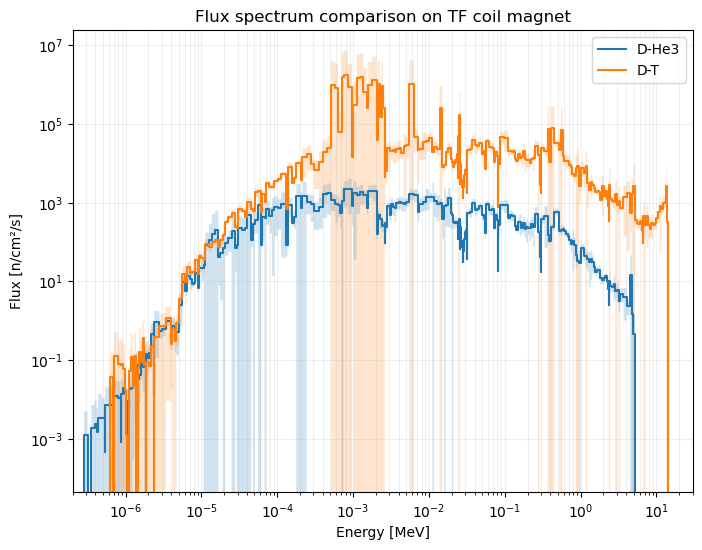


--- D-He3 ---
Total flux   = 9.587e+04 ± 2.209e+03 n/cm²/s
Flux > 7 MeV = 0.000e+00 ± 0.000e+00 n/cm²/s
Flux 1–7 MeV = 5.242e+02 ± 2.069e+01 n/cm²/s
Flux < 1 MeV = 9.535e+04 ± 2.209e+03 n/cm²/s

--- D-T ---
Total flux   = 1.875e+07 ± 4.266e+06 n/cm²/s
Flux > 7 MeV = 9.667e+03 ± 2.007e+03 n/cm²/s
Flux 1–7 MeV = 7.223e+04 ± 5.254e+03 n/cm²/s
Flux < 1 MeV = 1.867e+07 ± 4.266e+06 n/cm²/s


In [ ]:
compare_flux_spectra(
    sp1=sp_dhe,
    name1="neutron_spectra_tf_coil_magnet",
    volume1=tf_coil_magnet_volume*1e6,
    number_of_neutrons_per_second1=number_of_neutrons_per_second_dhe,
    sp2=sp_dt,
    name2="neutron_spectra_tf_coil_magnet",
    volume2=tf_coil_magnet_volume*1e6,
    number_of_neutrons_per_second2=number_of_neutrons_per_second_dt,
    label1="D-He3",
    label2="D-T",
    region_name="TF coil magnet"
)

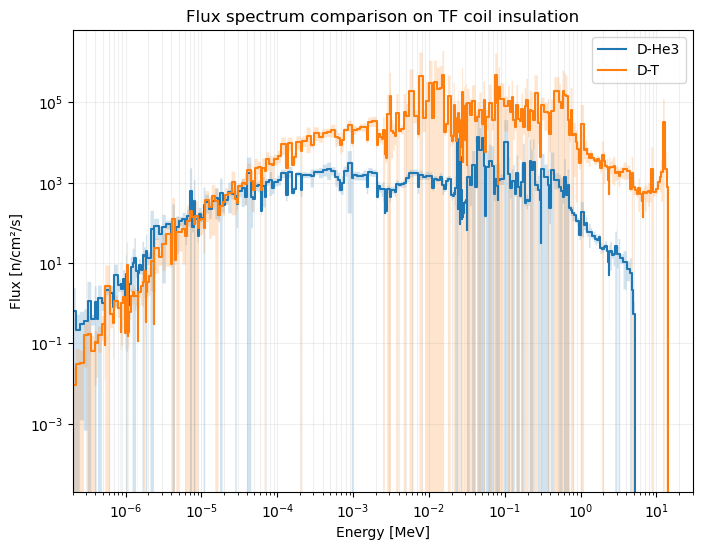


--- D-He3 ---
Total flux   = 2.234e+05 ± 2.454e+04 n/cm²/s
Flux > 7 MeV = 0.000e+00 ± 0.000e+00 n/cm²/s
Flux 1–7 MeV = 1.077e+03 ± 5.532e+01 n/cm²/s
Flux < 1 MeV = 2.223e+05 ± 2.454e+04 n/cm²/s

--- D-T ---
Total flux   = 8.948e+06 ± 1.006e+06 n/cm²/s
Flux > 7 MeV = 4.767e+04 ± 2.910e+04 n/cm²/s
Flux 1–7 MeV = 1.206e+05 ± 1.936e+04 n/cm²/s
Flux < 1 MeV = 8.780e+06 ± 1.005e+06 n/cm²/s


In [ ]:
compare_flux_spectra(
    sp1=sp_dhe,
    name1="neutron_spectra_tf_coil_insulation",
    volume1=tf_coil_insulation_volume*1e6,
    number_of_neutrons_per_second1=number_of_neutrons_per_second_dhe,
    sp2=sp_dt,
    name2="neutron_spectra_tf_coil_insulation",
    volume2=tf_coil_insulation_volume*1e6,
    number_of_neutrons_per_second2=number_of_neutrons_per_second_dt,
    label1="D-He3",
    label2="D-T",
    region_name="TF coil insulation"
)

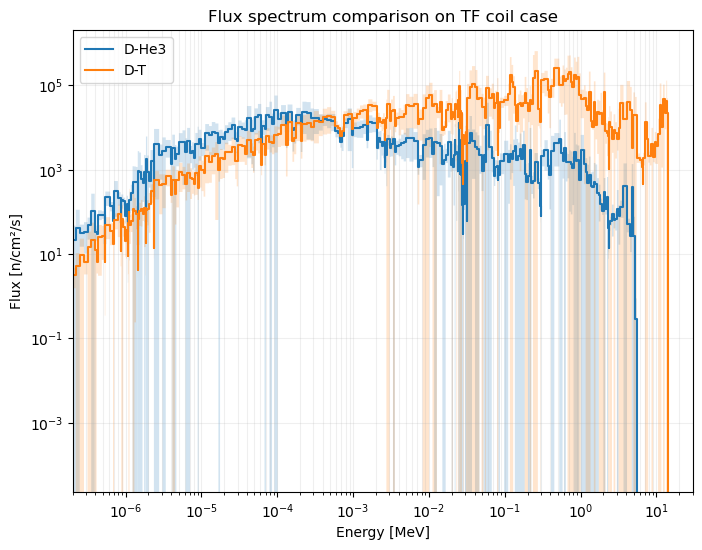


--- D-He3 ---
Total flux   = 1.063e+06 ± 2.987e+04 n/cm²/s
Flux > 7 MeV = 0.000e+00 ± 0.000e+00 n/cm²/s
Flux 1–7 MeV = 1.124e+04 ± 1.665e+03 n/cm²/s
Flux < 1 MeV = 1.052e+06 ± 2.982e+04 n/cm²/s

--- D-T ---
Total flux   = 7.504e+06 ± 3.768e+05 n/cm²/s
Flux > 7 MeV = 2.216e+05 ± 4.577e+04 n/cm²/s
Flux 1–7 MeV = 7.089e+05 ± 9.134e+04 n/cm²/s
Flux < 1 MeV = 6.573e+06 ± 3.627e+05 n/cm²/s


In [ ]:
compare_flux_spectra(
    sp1=sp_dhe,
    name1="neutron_spectra_tf_coil_case",
    volume1=tf_coil_case_volume*1e6,
    number_of_neutrons_per_second1=number_of_neutrons_per_second_dhe,
    sp2=sp_dt,
    name2="neutron_spectra_tf_coil_case",
    volume2=tf_coil_case_volume*1e6,
    number_of_neutrons_per_second2=number_of_neutrons_per_second_dt,
    label1="D-He3",
    label2="D-T",
    region_name="TF coil case"
)